# 01 · Exploration: first look at the Netflix data

Goal: understand the raw `netflix_titles.csv` before cleaning. What columns exist, how much is missing,
and which columns need parsing (dates, durations, list columns).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
df = pd.read_csv("../data/raw/netflix_titles.csv")
print(df.shape)
df.head()

(8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## Columns and types
Everything except `release_year` is loaded as text, so dates and durations need parsing.

In [2]:
df.dtypes

show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

## Duplicates and missing values

In [3]:
print("duplicate show_id:", df["show_id"].duplicated().sum())
print("duplicate rows:", df.duplicated().sum())

missing = df.isna().sum().to_frame("missing")
missing["pct"] = (missing["missing"] / len(df) * 100).round(1)
missing.sort_values("missing", ascending=False)

duplicate show_id: 0
duplicate rows: 0


,missing,pct
director,2634,29.9
country,831,9.4
cast,825,9.4
date_added,10,0.1
rating,4,0.0
duration,3,0.0
show_id,0,0.0
type,0,0.0
title,0,0.0
release_year,0,0.0


`director`, `country` and `cast` have the most gaps. These are the ones to fill from the TMDB API later.

## Movies vs TV shows

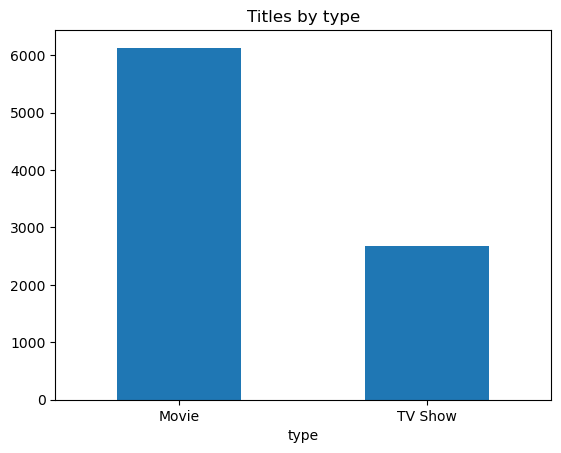

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

In [4]:
df["type"].value_counts().plot.bar(title="Titles by type", rot=0)
plt.show()
df["type"].value_counts()

## Content added per year

unparsed dates: 10


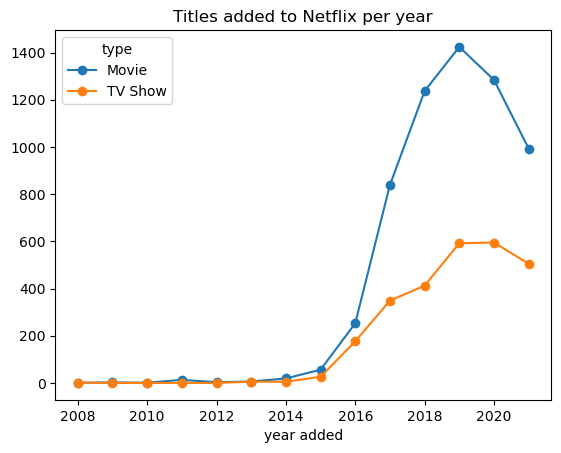

In [5]:
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%B %d, %Y", errors="coerce")
print("unparsed dates:", df["date_added"].isna().sum())

added = df.groupby([df["date_added"].dt.year, "type"]).size().unstack(fill_value=0)
added.plot(title="Titles added to Netflix per year", marker="o")
plt.xlabel("year added")
plt.show()

## Ratings
A few `rating` values are actually durations (e.g. `74 min`) that slipped into the wrong column, so they need fixing.

In [6]:
df["rating"].value_counts()

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64

In [7]:
df[df["rating"].str.contains("min", na=False)][["title", "rating", "duration"]]

,title,rating,duration
5541,Louis C.K. 2017,74 min,NaN
5794,Louis C.K.: Hilarious,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,66 min,NaN


## Duration
Movies use minutes and shows use seasons, so `duration` must be split into a number and a unit.

In [8]:
dur = df["duration"].str.extract(r"(?P<value>\d+)\s*(?P<unit>\w+)")
dur["value"] = pd.to_numeric(dur["value"])
dur.groupby(df["type"])["value"].describe()

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Movie,6128.0,99.577187,28.290593,3.0,87.0,98.0,114.0,312.0
TV Show,2676.0,1.764948,1.582752,1.0,1.0,1.0,2.0,17.0


## List columns: countries and genres
`country`, `listed_in` and `cast` hold comma-separated lists, so they need exploding before counting.

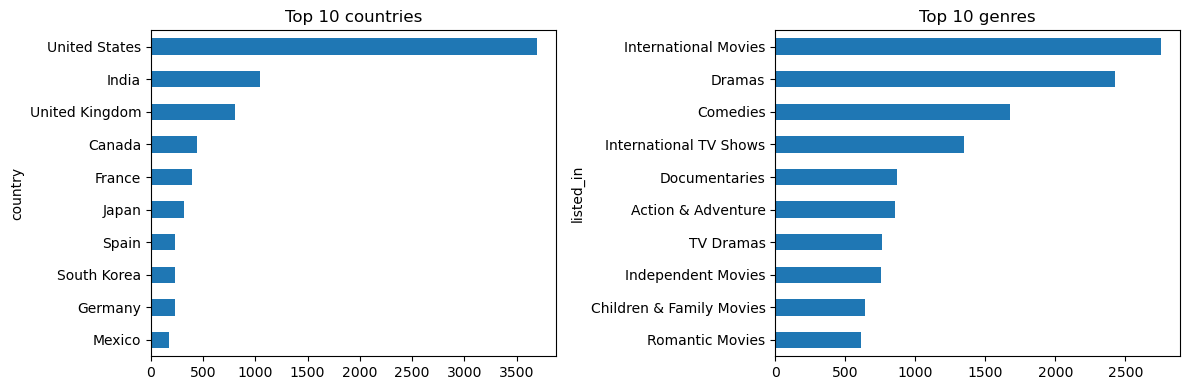

In [9]:
def top_values(col, n=10):
    return df[col].dropna().str.split(",").explode().str.strip().value_counts().head(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top_values("country").sort_values().plot.barh(ax=axes[0], title="Top 10 countries")
top_values("listed_in").sort_values().plot.barh(ax=axes[1], title="Top 10 genres")
plt.tight_layout()
plt.show()

## Takeaways for cleaning
- Parse `date_added` to a date (strip whitespace first).
- Move the minute values out of `rating` back into `duration`.
- Split `duration` into `duration_value` and `duration_unit`.
- Explode `cast`, `country` and `listed_in` into bridge tables for the star schema.
- Fill `director`, `country` and `cast` from TMDB and record the source column.